# Interpretable weight-space programming: spring-mass-damper

Notebook 2 consolidates the former iWSP scripts. The physical problem, feature
model, budgets, candidate histories, selection rules, metrics and test grids are
unchanged. It imports shared physics and baseline functions from `common.py`.

**Run all** replays/evaluates saved candidates and recomputes local baselines;
it does not launch LLM agents. Historical inputs stay in `iwsp_results/` and
new calculations go to `iwsp_rerun/`. The original ten-seed baseline results
are read by default; rerun them in notebook 1 if needed.

The agent model identifier, token usage and cost remain unrecorded for historical
iWSP sessions; see `EXPERIMENT_PROVENANCE.md`. This reorganization supplies no
new experiment evidence and changes no historical claims.

In [1]:
import copy, json, math, sys, time
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import display, Image
HERE = Path.cwd() if (Path.cwd() / 'common.py').is_file() else Path.cwd() / 'weight_paced_programming'
sys.path.insert(0, str(HERE))
from common import (T, THELD, EXTRA, Net, terms, diagnostics, train, fixed_features,
                    metrics, replay_patches, numerical_reference as reference)
SOURCE_RESULTS = HERE / 'iwsp_results'
OUTPUT = HERE / 'iwsp_rerun'
OUTPUT.mkdir(exist_ok=True)
BASELINE_FILE = SOURCE_RESULTS / 'ten_seed_baselines.json'
print('Historical inputs:', SOURCE_RESULTS.name, '| new outputs:', OUTPUT.name)

Historical inputs: iwsp_results | new outputs: iwsp_rerun


## Physics and programmed representation
The equation is x'' + 0.4x' + 4x = 0, with x(0)=1 and x'(0)=0.
Collocation remains 101 points over [0,10]; evaluation uses the original 1,000
points from 0.005 to 9.995 and the added 1,000 points from 10.005 to 20.

The four-coefficient feature architecture below was prescribed to the agents.
No fitting or parameter optimization is used; autograd supplies time derivatives
for the physics evaluator only.

In [2]:
class Program(torch.nn.Module):
    """Fixed oscillator feature multiplied by a rational damping feature."""
    def __init__(self, frequency, damping, curvature, linear):
        super().__init__()
        self.frequency, self.damping = frequency, damping
        self.curvature, self.linear = curvature, linear

    def forward(self, t):
        # Explicit feature computations, not learned parameters. A rational envelope
        # approximates dissipation; it is deliberately not the exact ODE solution.
        envelope = (1 + self.linear*t) / (1 + self.damping*t + self.curvature*t*t)
        return envelope * torch.cos(self.frequency*t)

## Physics-only feedback for a candidate
This is the unchanged validation and budget logic from `iwsp_feedback.py`, now a
notebook function. It records calls under `OUTPUT`, not in the historical ledgers.
An external agent supplies the candidate JSON file; this function is not an LLM.
Calling it is optional. Existing historical prompts referring to the former CLI
remain historical records and are preserved in the archive.

In [3]:
def evaluate_candidate(session, candidate_path, budget=3):
    candidate_path = Path(candidate_path)
    if not session.isalnum() or not 1 <= budget <= 100:
        raise ValueError('session must be alphanumeric and budget must be in 1..100')
    path = OUTPUT / ('session_' + session + '.json')
    path.parent.mkdir(exist_ok=True)
    state = json.loads(path.read_text()) if path.exists() else {'budget': budget, 'candidates': []}
    if state['budget'] != budget or len(state['candidates']) >= state['budget']:
        raise SystemExit('Budget mismatch or evaluation budget exhausted')
    candidate = json.loads(candidate_path.read_text())
    keys = ['frequency', 'damping', 'curvature', 'linear']
    if set(candidate) != set(keys + ['explanation']) or not isinstance(candidate['explanation'], str):
        raise SystemExit('Expected four numeric coefficients and an explanation')
    if any(type(candidate[k]) not in (float, int) or not math.isfinite(candidate[k]) or
           abs(candidate[k]) > 10 for k in keys):
        raise SystemExit('Invalid coefficient')
    # Positive denominator on the entire development and evaluation interval.
    if candidate['damping'] < 0 or candidate['curvature'] < 0:
        raise SystemExit('Damping and curvature must be nonnegative')
    start = time.perf_counter()
    result = diagnostics(Program(*(candidate[k] for k in keys)), 'free')
    state['candidates'].append({'candidate': candidate, 'feedback': result,
                                'seconds': time.perf_counter()-start, 'physics_evaluations': 2})
    path.write_text(json.dumps(state, indent=2), encoding='utf-8')
    print(json.dumps(result, indent=2))


In [4]:
# Optional new-session feedback (uncomment after supplying a candidate):
# evaluate_candidate('newrun', HERE / 'my_candidate.json', budget=3)

## Original comparison, recorded patches and demonstration candidates
Moved from `iwsp_experiment.py`. The PINN/partial checkpoint are recreated with
seed 42, and the original WSP patches are replayed from the recorded JSON history.
The nine predeclared candidates remain labeled demonstrations. Selected candidates
from the three earlier agent sessions are read from the historical session files.
This does not generate fresh LLM attempts.

In [5]:
def reproduce_pilot(out):
    out.mkdir(parents=True, exist_ok=True)
    # Recreate notebook model, initialization, optimizer and training schedule.
    initial = Net(42)
    pinn = copy.deepcopy(initial)
    pinn_time = train(pinn, 'free', 3000)
    partial = copy.deepcopy(initial)
    train(partial, 'free', 200)
    ls, ls_time, _ = fixed_features(initial, 'free')
    models = {'PINN': pinn, 'least_squares': ls}
    for name, model in replay_patches({'zero': Net(42, True), 'xavier': copy.deepcopy(initial),
                                        'partial': partial}).items():
        models['WSP_'+name] = model

    # Three predeclared, manually authored sequences. Each is a separate design
    # trajectory, not an independent LLM session or a stochastic replicate.
    proposals = [
        [(2., .2, .02, .2), (2., .2, .04, .2), (2., .2, .08, .2)],
        [(1.8, .3, .03, .3), (1.9, .3, .06, .3), (2., .3, .06, .3)],
        [(2.2, .1, .02, .1), (2.1, .1, .04, .1), (2., .1, .06, .1)],
    ]
    ledger = []
    for attempt, sequence in enumerate(proposals, 1):
        best = None
        for iteration, p in enumerate(sequence, 1):
            start = time.perf_counter()
            model = Program(*p)
            feedback = diagnostics(model, 'free')
            elapsed = time.perf_counter()-start
            entry = {'attempt': attempt, 'iteration': iteration, 'parameters': dict(zip(
                ['frequency', 'damping', 'curvature', 'linear'], p)),
                'architecture': 'cosine feature times rational damping feature',
                'interpretation': 'frequency controls oscillations; rational envelope approximates energy decay',
                'change': 'initial proposal' if iteration == 1 else 'revised fixed feature coefficients',
                'training_feedback': feedback, 'physics_evaluations': 2, 'evaluation_seconds': elapsed}
            ledger.append(entry)
            if best is None or feedback['loss'] < best[0]:
                best = (feedback['loss'], model, iteration)
        models[f'iWSP_design_{attempt}'] = best[1]
        ledger[-1]['selected_iteration'] = best[2]

    sessions = {}
    for session in ('attemptone', 'attempttwo', 'attemptthree'):
        path = SOURCE_RESULTS / f'session_{session}.json'
        if not path.exists():
            continue
        state = json.loads(path.read_text(encoding='utf-8'))
        if not state['candidates']:
            continue
        selected = min(state['candidates'], key=lambda c: c['feedback']['loss'])
        p = selected['candidate']
        name = 'iWSP_agent_' + session
        models[name] = Program(*(p[k] for k in ('frequency', 'damping', 'curvature', 'linear')))
        sessions[name] = state

    results = {}
    for name, model in models.items():
        results[name] = {'heldout_0_10': metrics(model, THELD), 'extrapolation_10_20': metrics(model, EXTRA),
                         'parameter_count': 4 if isinstance(model, Program) else sum(p.numel() for p in model.parameters())}
    results['PINN'].update(training_seconds=pinn_time, physics_evaluations=6000)
    results['least_squares'].update(training_seconds=ls_time, physics_evaluations=36)
    # WSP reported counts and agent costs come from the original recorded run.
    results['WSP_zero'].update(physics_evaluations=8, agent_calls=2, estimated_usd=.01837)
    results['WSP_xavier'].update(physics_evaluations=8, agent_calls=2, estimated_usd=.0372)
    results['WSP_partial'].update(physics_evaluations=406, agent_calls=2, estimated_usd=.043873)
    for i in range(1, 4):
        results[f'iWSP_design_{i}'].update(candidate_evaluations=3, physics_evaluations=6,
                                          llm_calls=0, independent_agent_attempt=False)
    for name, state in sessions.items():
        results[name].update(candidate_evaluations=len(state['candidates']),
                             physics_evaluations=sum(c['physics_evaluations'] for c in state['candidates']),
                             agent_sessions=1, agent_token_cost='not available', independent_agent_attempt=True)
    (out/'candidates.json').write_text(json.dumps(ledger, indent=2), encoding='utf-8')
    (out/'metrics.json').write_text(json.dumps(results, indent=2), encoding='utf-8')
    grid = np.linspace(0, 20, 2001)
    target = reference(grid)
    fig, axes = plt.subplots(3, 1, figsize=(11, 11), sharex=True)
    axes[0].plot(grid, target, color='black', label='numerical reference', linewidth=2)
    for name, model in models.items():
        t = torch.tensor(grid[:, None])
        x, _, r = terms(model, t, 'free', False)
        pred = x.detach().numpy().ravel()
        axes[0].plot(grid, pred, label=name, alpha=.75)
        axes[1].plot(grid, r.detach().numpy().ravel(), label=name, alpha=.75)
        axes[2].plot(grid, np.abs(pred-target), label=name, alpha=.75)
    for ax, title in zip(axes, ['Displacement', 'Physics residual', 'Absolute trajectory error']):
        ax.axvline(10, color='black', linestyle='--', alpha=.5)
        ax.set_ylabel(title); ax.grid(alpha=.2)
    axes[0].legend(ncol=3, fontsize=8); axes[-1].set_xlabel('Time')
    fig.tight_layout(); fig.savefig(out/'comparison.png', dpi=160); plt.close(fig)
    fig, axes = plt.subplots(2, 1, figsize=(11, 8))
    for ax, grid, title in zip(axes, (THELD, EXTRA), ('Original held-out window', 'Added extrapolation window')):
        ax.plot(grid, reference(grid), color='black', linewidth=2, label='reference')
        for name, model in models.items():
            if name.startswith('iWSP_agent_') or name in ('PINN', 'WSP_xavier'):
                with torch.no_grad():
                    pred = model(torch.tensor(grid[:, None])).numpy().ravel()
                ax.plot(grid, pred, label=name, alpha=.85)
        ax.set_title(title); ax.set_ylabel('Displacement'); ax.grid(alpha=.2)
    axes[0].legend(ncol=2, fontsize=8); axes[-1].set_xlabel('Time')
    fig.tight_layout(); fig.savefig(out/'agent_trajectories.png', dpi=160); plt.close(fig)
    print(json.dumps(results, indent=2))

In [6]:
reproduce_pilot(OUTPUT)

{
  "PINN": {
    "heldout_0_10": {
      "relative_l2": 0.3647288726394624,
      "residual_rmse": 0.16100671669441344,
      "ic_position_abs": 0.027864821072063006,
      "ic_velocity_abs": 6.921515586193888e-05,
      "ic_error": 0.027864907035837883
    },
    "extrapolation_10_20": {
      "relative_l2": 3.151967633112558,
      "residual_rmse": 0.5454129990091564,
      "ic_position_abs": 0.027864821072063006,
      "ic_velocity_abs": 6.921515586193888e-05,
      "ic_error": 0.027864907035837883
    },
    "parameter_count": 321,
    "training_seconds": 9.217909399994824,
    "physics_evaluations": 6000
  },
  "least_squares": {
    "heldout_0_10": {
      "relative_l2": 0.18259023056425402,
      "residual_rmse": 0.27455636421751517,
      "ic_position_abs": 0.1682943404281826,
      "ic_velocity_abs": 0.017016593366861343,
      "ic_error": 0.16915244446939015
    },
    "extrapolation_10_20": {
      "relative_l2": 93088.60052148411,
      "residual_rmse": 18688.813413256317,

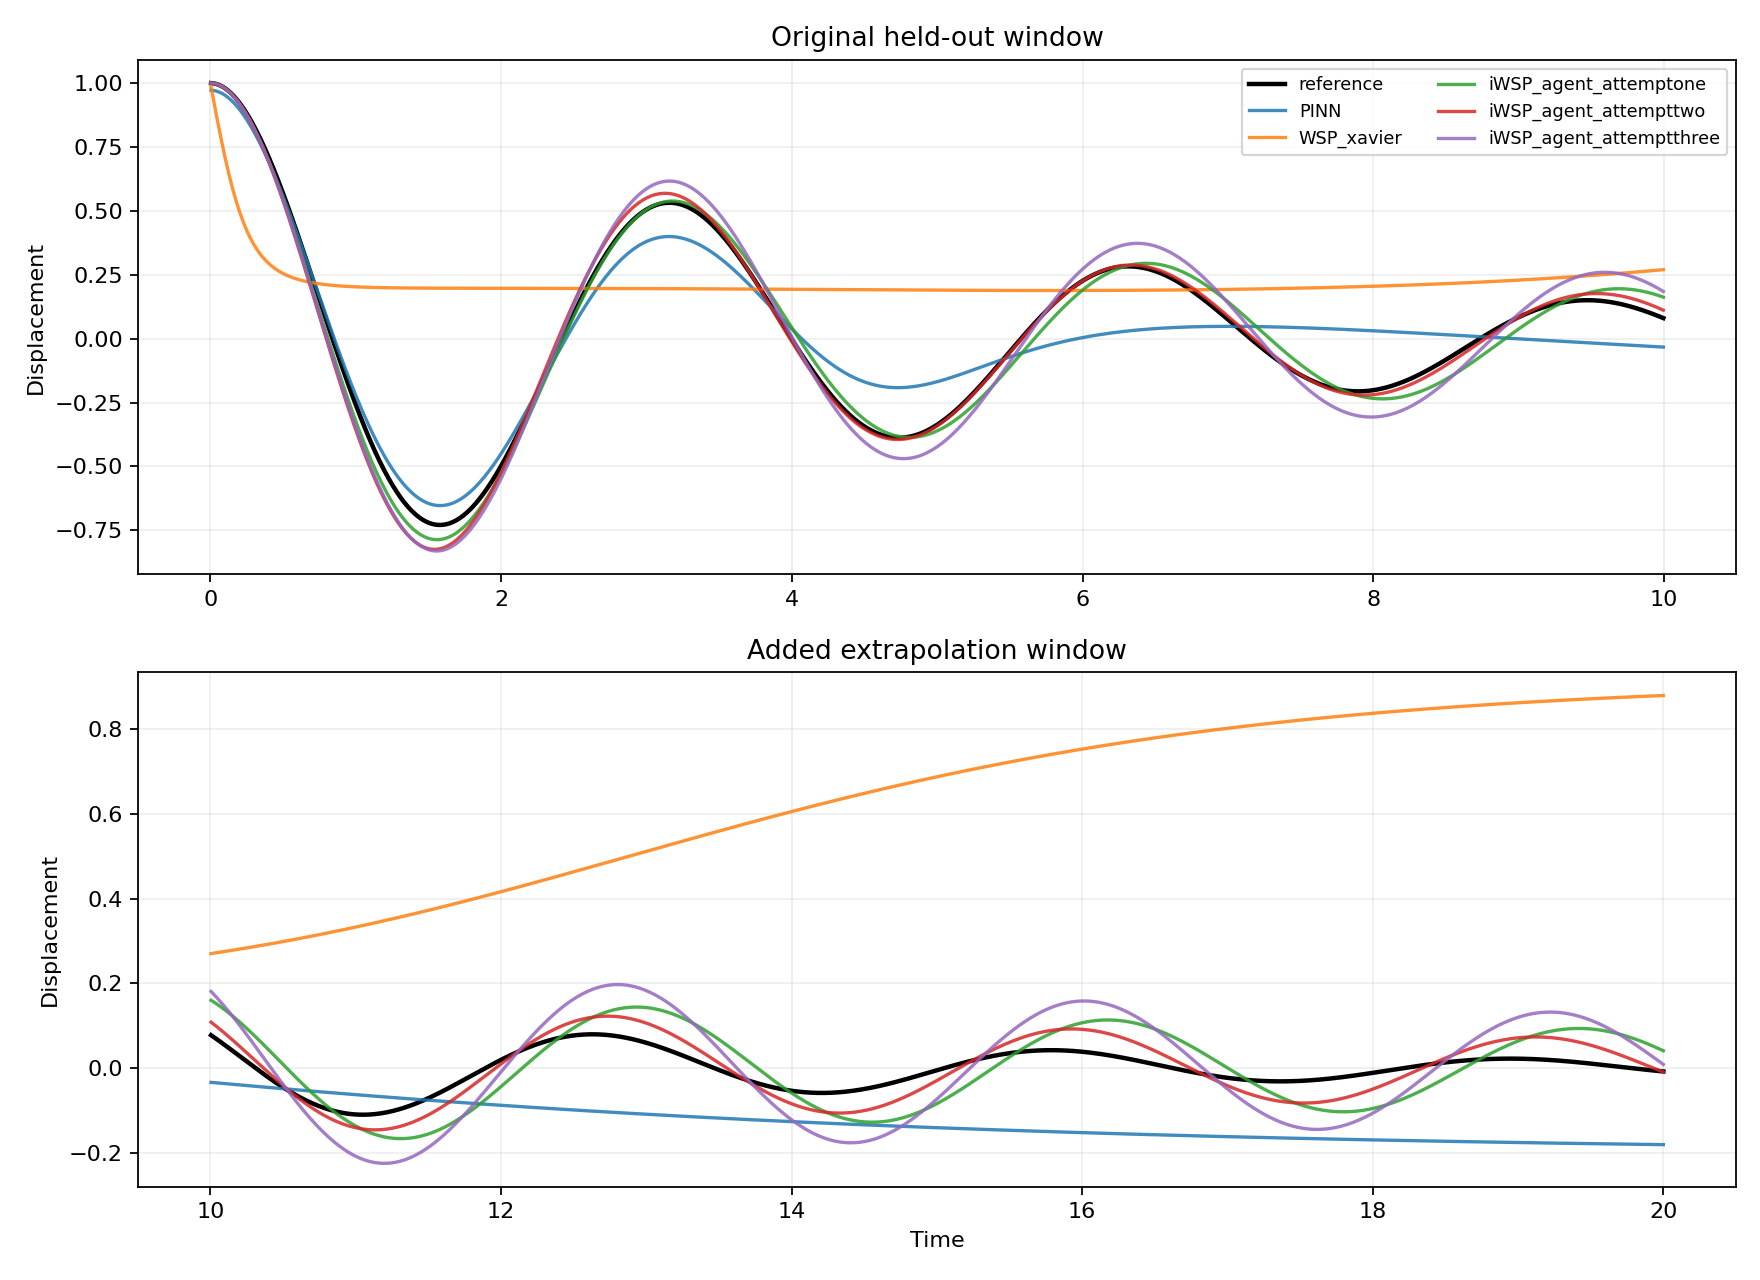

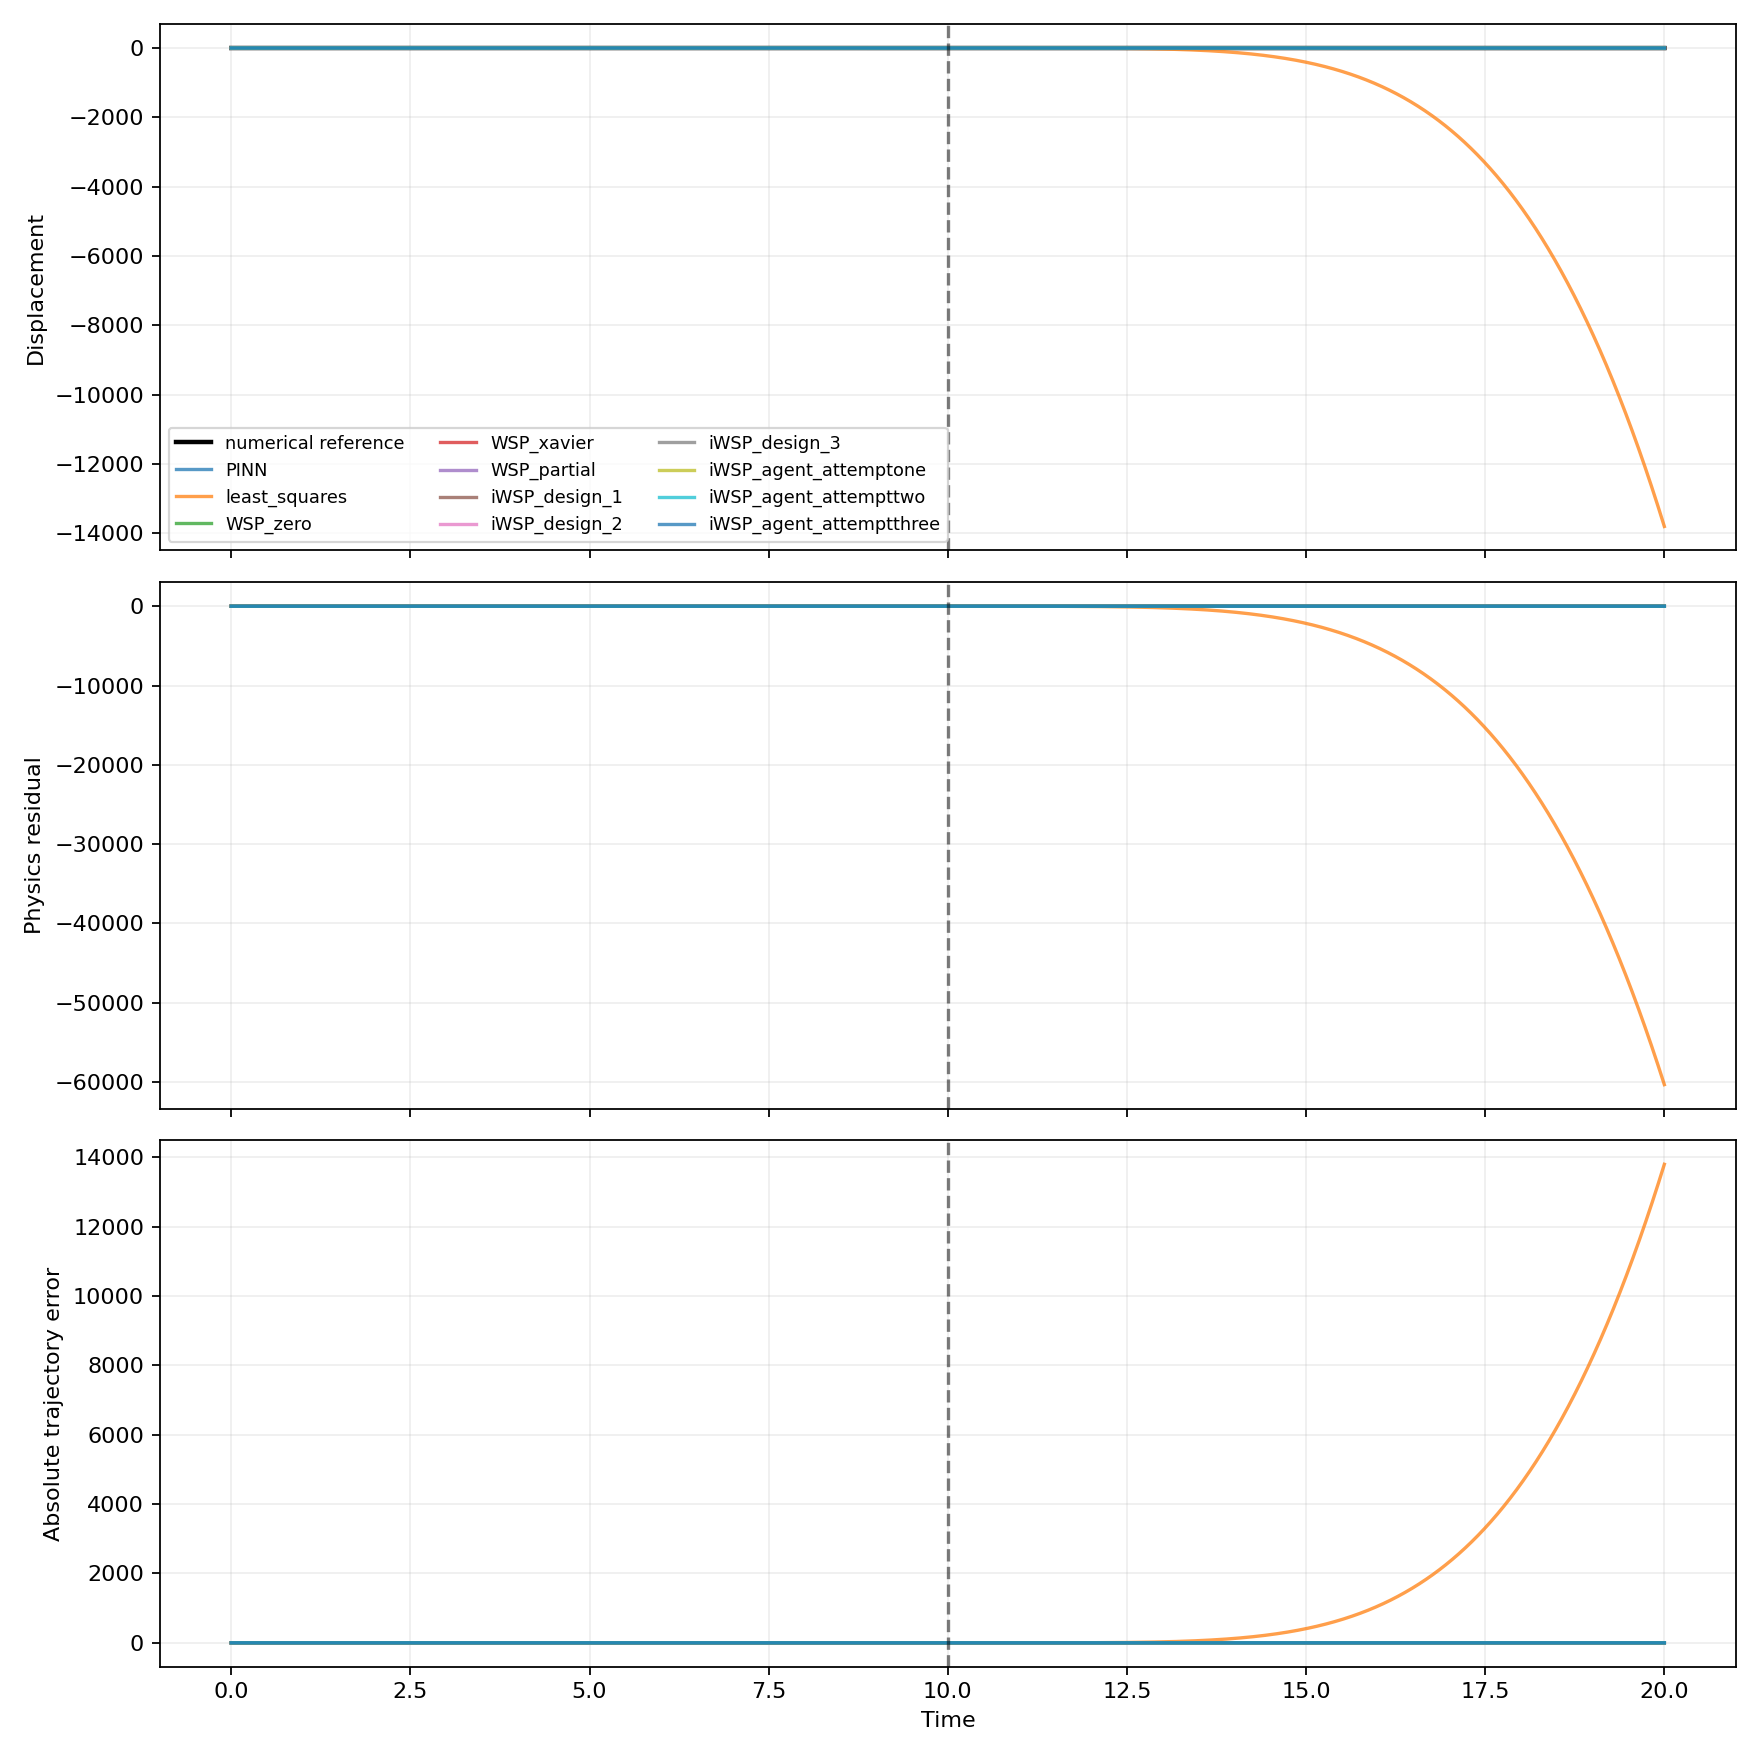

In [7]:
display(Image(filename=str(OUTPUT / 'agent_trajectories.png')))
display(Image(filename=str(OUTPUT / 'comparison.png')))

## Ten-session follow-up
Moved from `evaluate_ten_trials.py`. Each saved session must have exactly three
candidates. Selection remains minimum collocation loss, and summary statistics
and plot definitions are unchanged. No test metric is returned to an agent here.

In [8]:
OUT = OUTPUT
records = []
for i in range(1, 11):
    path = SOURCE_RESULTS / f'session_trial{i:02}.json'
    if not path.exists():
        raise SystemExit(f'Missing closed session: {path}')
    state = json.loads(path.read_text(encoding='utf-8'))
    if state['budget'] != 3 or len(state['candidates']) != 3:
        raise SystemExit(f'Incomplete session: {path}')
    selected_index = min(range(3), key=lambda j: state['candidates'][j]['feedback']['loss'])
    selected = state['candidates'][selected_index]
    p = selected['candidate']
    model = Program(*(p[k] for k in ('frequency', 'damping', 'curvature', 'linear')))
    records.append({'trial': i, 'selected_iteration': selected_index+1, 'parameters': p,
                    'collocation_loss': selected['feedback']['loss'],
                    'heldout_0_10': metrics(model, THELD),
                    'extrapolation_10_20': metrics(model, EXTRA),
                    'candidate_evaluations': 3,
                    'feedback_seconds': sum(c['seconds'] for c in state['candidates'])})

baseline = json.loads((OUT/'metrics.json').read_text(encoding='utf-8'))
replicates = json.loads(BASELINE_FILE.read_text(encoding='utf-8'))
if not replicates['complete'] or len(replicates['trials']) != 10:
    raise SystemExit('Ten-seed baseline run is incomplete')
summary = {}
for split in ('heldout_0_10', 'extrapolation_10_20'):
    values = np.array([r[split]['relative_l2'] for r in records])
    summary[split] = {'mean': float(values.mean()), 'sample_std': float(values.std(ddof=1)),
                      'median': float(np.median(values)), 'min': float(values.min()),
                      'max': float(values.max()),
                      'below_pinn_count': int((values < baseline['PINN'][split]['relative_l2']).sum()),
                      'below_ls_count': int((values < baseline['least_squares'][split]['relative_l2']).sum()),
                      'below_wsp_xavier_count': int((values < baseline['WSP_xavier'][split]['relative_l2']).sum())}
    for name in ('PINN', 'least_squares'):
        b = np.array([r[name][split]['relative_l2'] for r in replicates['trials']])
        summary[split][name+'_ten_seeds'] = {'mean': float(b.mean()), 'sample_std': float(b.std(ddof=1)),
                                              'median': float(np.median(b)), 'min': float(b.min()), 'max': float(b.max())}
result = {'protocol': '10 fresh sessions, 3 calls each, physics loss selection',
          'trials': records, 'summary': summary,
          'comparison': {name: {split: baseline[name][split] for split in ('heldout_0_10', 'extrapolation_10_20')}
                         for name in ('PINN', 'least_squares', 'WSP_xavier')}}
(OUT/'ten_trials.json').write_text(json.dumps(result, indent=2), encoding='utf-8')
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, split, title in zip(axes, ('heldout_0_10', 'extrapolation_10_20'), ('Held-out [0,10]', 'Extrapolation [10,20]')):
    vals = [r[split]['relative_l2'] for r in records]
    ax.scatter(range(1, 11), vals, label='iWSP attempts')
    for name in ('PINN', 'least_squares'):
        vals_baseline = [r[name][split]['relative_l2'] for r in replicates['trials']]
        ax.scatter(range(1, 11), vals_baseline, marker='x', label=name + ' seeds')
    ax.axhline(baseline['WSP_xavier'][split]['relative_l2'], linestyle='--', label='WSP Xavier pilot')
    ax.set_yscale('log'); ax.set_title(title); ax.set_xlabel('Attempt'); ax.set_ylabel('Relative L2 (log scale)')
    ax.grid(alpha=.2); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT/'ten_trials.png', dpi=160)
print(json.dumps(summary, indent=2))


{
  "heldout_0_10": {
    "mean": 0.15498478826946976,
    "sample_std": 0.0475153459830289,
    "median": 0.136661654782182,
    "min": 0.10437721200319852,
    "max": 0.2402201067979899,
    "below_pinn_count": 10,
    "below_ls_count": 8,
    "below_wsp_xavier_count": 10,
    "PINN_ten_seeds": {
      "mean": 0.4414541647320271,
      "sample_std": 0.07096122140196952,
      "median": 0.4494068103108714,
      "min": 0.3148457398465148,
      "max": 0.531005558485751
    },
    "least_squares_ten_seeds": {
      "mean": 0.18773036691396944,
      "sample_std": 0.012281368111332151,
      "median": 0.18562489022228593,
      "min": 0.17132977605535224,
      "max": 0.20729242180830093
    }
  },
  "extrapolation_10_20": {
    "mean": 1.324768091082965,
    "sample_std": 0.5168395683532708,
    "median": 1.2227310665511504,
    "min": 0.7422526746554384,
    "max": 2.2069807134256827,
    "below_pinn_count": 10,
    "below_ls_count": 10,
    "below_wsp_xavier_count": 10,
    "PINN_ten

## Independent reconstruction check
The two implementations below were independently produced in earlier fresh
agent sessions from concise explanations. They are moved verbatim here; this
is not a new blind reconstruction. The first was a demonstration; the second
rebuilds the best-physics-loss candidate from the three-session agent pilot.

In [9]:
import torch
from torch import nn


class DemonstrationReconstructed(nn.Module):
    def forward(self, t: torch.Tensor) -> torch.Tensor:
        envelope = (1 + 0.2 * t) / (1 + 0.2 * t + 0.08 * t.square())
        return torch.cos(2 * t) * envelope


In [10]:
import torch
from torch import nn


class Reconstructed(nn.Module):
    """Cosine feature modulated by a rational damping envelope."""

    def forward(self, t: torch.Tensor) -> torch.Tensor:
        envelope = (1 + 0.25 * t) / (1 + 0.25 * t + 0.15 * t.square())
        return torch.cos(1.94 * t) * envelope



In [11]:
original = Program(1.94, .25, .15, .25)  # best agent candidate by collocation loss
rebuilt = Reconstructed()
description = ('The output is a cosine feature with angular frequency 1.94 multiplied by '
               'a rational damping envelope. Its numerator is 1 + 0.25t and its '
               'denominator is 1 + 0.25t + 0.15t².')
result = {'selection': 'lowest collocation loss across the three agent sessions',
          'description': description, 'description_words': len(description.split()), 'grids': {}}
for name, grid in [('collocation', T.numpy().ravel()), ('heldout', THELD), ('extrapolation', EXTRA)]:
    with torch.no_grad():
        a = original(torch.tensor(grid[:, None])).numpy().ravel()
        b = rebuilt(torch.tensor(grid[:, None])).numpy().ravel()
    result['grids'][name] = {'max_absolute_difference': float(np.max(np.abs(a-b))),
                             'relative_l2_difference': float(np.linalg.norm(a-b)/np.linalg.norm(a)),
                             'rebuilt_metrics': metrics(rebuilt, grid)}
path = OUTPUT / 'reconstruction.json'
path.write_text(json.dumps(result, indent=2), encoding='utf-8')
print(json.dumps(result, indent=2))


{
  "selection": "lowest collocation loss across the three agent sessions",
  "description": "The output is a cosine feature with angular frequency 1.94 multiplied by a rational damping envelope. Its numerator is 1 + 0.25t and its denominator is 1 + 0.25t + 0.15t\u00b2.",
  "description_words": 31,
  "grids": {
    "collocation": {
      "max_absolute_difference": 1.1102230246251565e-16,
      "relative_l2_difference": 6.357582248192423e-17,
      "rebuilt_metrics": {
        "relative_l2": 0.12166718499084941,
        "residual_rmse": 0.09541196789627647,
        "ic_position_abs": 0.0,
        "ic_velocity_abs": 0.0,
        "ic_error": 0.0
      }
    },
    "heldout": {
      "max_absolute_difference": 1.1102230246251565e-16,
      "relative_l2_difference": 5.2828657020581527e-17,
      "rebuilt_metrics": {
        "relative_l2": 0.12295611981475747,
        "residual_rmse": 0.09586287266876105,
        "ic_position_abs": 0.0,
        "ic_velocity_abs": 0.0,
        "ic_error": 0.0

## Files and reproduction scope
- `01_wsp.ipynb`: original WSP API pilot, PINN/least-squares baselines and optional ten-seed reruns.
- `02_iwsp.ipynb`: iWSP representation, feedback, saved-candidate comparisons, plots and reconstruction.
- `common.py`: shared numerical implementations; importing it makes no network requests.
- `iwsp_results/`: preserved historical results and extracted original WSP patch history.
- `wsp_rerun/`, `iwsp_rerun/`: separate outputs from rerunning these notebooks.
- `archive/before_notebook_consolidation.zip`: exact original source files for provenance.

The split changes file organization and output destinations only. Historical
model/cost gaps and experimental limitations remain documented in the reports.